# SMS Spam Pattern Mining

Discover and interpret linguistic and structural patterns that distinguish spam from legitimate (ham) SMS in the UCI SMS Spam Collection. Pattern discovery is the main goal; the classifier is a secondary baseline.

## Table of contents

1. Introduction and objectives
2. Setup and data loading
3. Cleaning
4. Read the messages
5. Exploratory data analysis
6. Text normalisation
7. Engineered pattern features
8. Statistical comparison
9. Word and phrase analysis
10. Spam families
11. Association rule mining
12. Interpretation and findings
13. Optional baseline classifiers
14. Conclusion and limitations

The notebook uses a fixed random seed, labels and thresholds in one configuration cell, and keeps raw messages for case-sensitive features. All evidence below is computed from the downloaded corpus; association is not causation.

## 1. Introduction and objectives

The UCI corpus contains labeled SMS texts (`ham` and `spam`). We will compare message length, normalized token patterns, URLs, phone-like numbers, currency, punctuation, capitalization, trigger phrases, and informal language. We also group spam into interpretable families and quantify uncertainty and multiple-testing error. The collection is old and UK-centric, so its patterns should not be treated as universal rules.

## 2. Setup and data loading

Install the requested libraries. This first cell is intended to run once in a standard Jupyter environment.

In [23]:

# 1. Import required libraries

from pathlib import Path
import csv
import io
import re
import zipfile
import html
import math
import requests

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from IPython.display import display, Markdown


# 2. Project settings

CONFIG = {
    'seed': 42,
    'test_size': 0.20,
    'min_doc_freq': 3,
    'feature_q_threshold': 0.05,
    'association_min_support': 0.01,
    'association_min_spam_confidence': 0.50,
    'n_families': 6,
    'local_data': Path(r'sms+spam+collection/SMSSpamCollection'),
    'sample_messages': 10
}


# 3. Set graph colours

HAM = '#2E8B57'
SPAM = '#D64B4B'

PALETTE = {
    'ham': HAM,
    'spam': SPAM
}


# 4. Set random seed

np.random.seed(CONFIG['seed'])


# 5. Set graph appearance

sns.set_theme(style='whitegrid', context='notebook', font_scale=1.05)

plt.rcParams['figure.dpi'] = 110
plt.rcParams['savefig.dpi'] = 140


In [24]:

# Load the SMS Spam dataset

df_raw = pd.read_csv(
    CONFIG['local_data'],
    sep='\t',
    header=None,
    names=['label', 'message'],
    quoting=csv.QUOTE_NONE,
    encoding='utf-8',
    on_bad_lines='warn'
)

# Check the dataset size
assert len(df_raw) == 5574, "Dataset should contain 5574 rows"

# Display basic information
print("Dataset shape:", df_raw.shape)

print("\nClass distribution:")
display(df_raw['label'].value_counts().to_frame('messages'))

# Check duplicate messages
print("\nDuplicate messages:")
duplicates = df_raw[df_raw.duplicated(['label', 'message'])]
display(duplicates.groupby('label').size().to_frame('duplicate_rows'))

# Check missing values
print("\nMissing values:")
display(df_raw.isnull().sum().to_frame('missing'))

# Display summary
spam_count = (df_raw['label'] == 'spam').sum()
ham_count = (df_raw['label'] == 'ham').sum()
duplicate_count = df_raw.duplicated(['label', 'message']).sum()

print("\nKey takeaway:")
print(f"Spam messages: {spam_count}")
print(f"Ham messages: {ham_count}")
print(f"Duplicate rows: {duplicate_count}")


Dataset shape: (5574, 2)

Class distribution:


,messages
label,
ham,4827
spam,747



Duplicate messages:


,duplicate_rows
label,
ham,309
spam,94



Missing values:


,missing
label,0
message,0



Key takeaway:
Spam messages: 747
Ham messages: 4827
Duplicate rows: 403


## 3. Cleaning

Normalize labels, drop missing rows and exact duplicates, retain `message_raw`, and add lowercase text. The corpus contains heavily templated spam; exact deduplication does not remove near-duplicates.

In [25]:

# Remove rows with missing labels or messages
df = df_raw.dropna(subset=['label', 'message']).copy()

# Standardize the labels
df['label'] = df['label'].str.strip().str.lower()

# Keep only ham and spam messages
df = df[df['label'].isin(['ham', 'spam'])].copy()

# Preserve original messages
df['message_raw'] = df['message'].astype(str)

# Count rows before removing duplicates
n_before = len(df)

# Remove exact duplicate messages
df = df.drop_duplicates(
    subset=['label', 'message_raw']
).reset_index(drop=True)

# Calculate removed duplicates
rows_removed = n_before - len(df)

# Create lowercase text for analysis
df['text_lower'] = df['message_raw'].str.lower()

# Display results
print(f"Exact duplicates removed: {rows_removed:,}")
print(f"Clean shape: {len(df):,} rows")

display(df['label'].value_counts().rename('messages').to_frame())

display(Markdown(
    f"**Key takeaway — cleaning:** Removed {rows_removed:,} exact duplicates; "
    f"{len(df):,} unique labeled messages remain. "
    "Near-duplicate spam templates remain, and raw case is preserved for feature extraction."
))


Exact duplicates removed: 403
Clean shape: 5,171 rows


,messages
label,
ham,4518
spam,653


**Key takeaway — cleaning:** Removed 403 exact duplicates; 5,171 unique labeled messages remain. Near-duplicate spam templates remain, and raw case is preserved for feature extraction.

## 4. Read the messages

Inspect a reproducible random sample from each class before defining patterns. The keyword-in-context helper returns up to five matching messages and their original class labels.

In [26]:

# Select random spam and ham messages

spam_samples = df[df['label'] == 'spam'].sample(
    n=CONFIG['sample_messages'],
    random_state=CONFIG['seed']
)

ham_samples = df[df['label'] == 'ham'].sample(
    n=CONFIG['sample_messages'],
    random_state=CONFIG['seed']
)

# Combine both samples
samples = pd.concat([spam_samples, ham_samples])

# Sort messages by label
samples = samples.sort_values('label').reset_index(drop=True)

# Display the sample messages
display(
    samples[['label', 'message_raw']].style.set_properties(
        **{
            'white-space': 'pre-wrap',
            'text-align': 'left'
        }
    )
)


# Function to search for a keyword in SMS messages

def keyword_in_context(keyword, n=5):

    # Search for the keyword as a complete word
    pattern = r'\b' + re.escape(keyword) + r'\b'

    matching_messages = df[
        df['message_raw'].str.contains(
            pattern,
            case=False,
            regex=True
        )
    ]

    # Return the first n matching messages
    return matching_messages[
        ['label', 'message_raw']
    ].head(n).reset_index(drop=True)


# Search for the word "claim"
display(keyword_in_context('claim', 5))


,label,message_raw
0,ham,Me too! Have a lovely night xxx
1,ham,"Well am officially in a philosophical hole, so if u wanna call am at home ready to be saved!"
2,ham,"New Theory: Argument wins d SITUATION, but loses the PERSON. So dont argue with ur friends just.. . . . kick them & say, I'm always correct.!"
3,ham,Do you know when the result.
4,ham,SO IS TH GOWER MATE WHICH IS WHERE I AM!?! HOW R U MAN? ALL IS GOOD IN WALES ILL B BACK MORROW. C U THIS WK? WHO WAS THE MSG 4?  RANDOM!
5,ham,Wah... Okie okie... Muz make use of e unlimited... Haha...
6,ham,Update your face book status frequently :)
7,ham,This girl does not stay in bed. This girl doesn't need recovery time. Id rather pass out while having fun then be cooped up in bed
8,ham,I'm putting it on now. It should be ready for <TIME>
9,ham,Gam gone after outstanding innings.


,label,message_raw
0,spam,WINNER!! As a valued network customer you have...
1,spam,URGENT! You have won a 1 week FREE membership ...
2,spam,Urgent UR awarded a complimentary trip to Euro...
3,spam,GENT! We are trying to contact you. Last weeke...
4,spam,You are a winner U have been specially selecte...


## 5. Exploratory data analysis

Compare class balance and message lengths in characters and whitespace-separated words. Histograms and boxplots show distribution shape and central tendency; boxplots omit extreme points for readability.

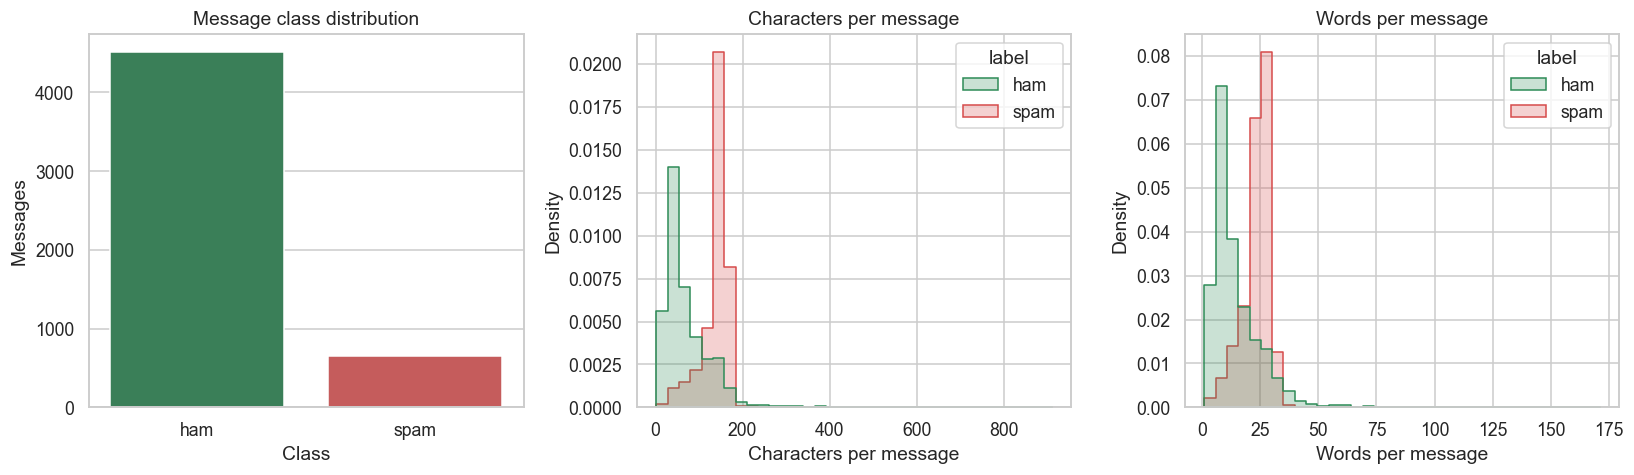

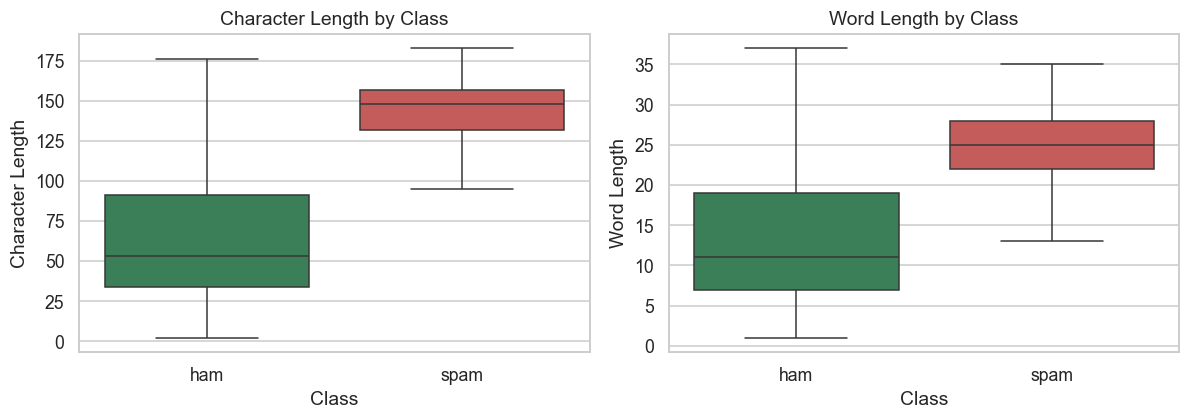

,measure,ham_median,spam_median,U,p_value,AUC_spam_longer,probability_superiority
0,char_length,53.0,148.0,2576428.5,0.0,0.8733,0.8733
1,word_length,11.0,25.0,2399824.0,0.0,0.8134,0.8134


**Key takeaway — message length:** Median characters: ham 53, spam 148; Mann–Whitney p=1.9e-209, probability of superiority=0.873.

In [27]:

# 1. Calculate message length

df['char_length'] = df['message_raw'].str.len()
df['word_length'] = df['message_raw'].str.split().str.len()


# 2. Display class distribution and message length graphs

fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# Number of spam and ham messages
sns.countplot(
    data=df,
    x='label',
    order=['ham', 'spam'],
    hue='label',
    palette=PALETTE,
    legend=False,
    ax=axes[0]
)

axes[0].set_title('Message class distribution')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Messages')


# Character and word length distributions
sns.histplot(
    data=df,
    x='char_length',
    hue='label',
    hue_order=['ham', 'spam'],
    palette=PALETTE,
    bins=35,
    element='step',
    stat='density',
    common_norm=False,
    ax=axes[1]
)

axes[1].set_title('Characters per message')
axes[1].set_xlabel('Characters per message')
axes[1].set_ylabel('Density')


sns.histplot(
    data=df,
    x='word_length',
    hue='label',
    hue_order=['ham', 'spam'],
    palette=PALETTE,
    bins=35,
    element='step',
    stat='density',
    common_norm=False,
    ax=axes[2]
)

axes[2].set_title('Words per message')
axes[2].set_xlabel('Words per message')
axes[2].set_ylabel('Density')

plt.tight_layout()
plt.show()


# 3. Compare message lengths using boxplots

fig, axes = plt.subplots(1, 2, figsize=(11, 4))

sns.boxplot(
    data=df,
    x='label',
    y='char_length',
    hue='label',
    order=['ham', 'spam'],
    hue_order=['ham', 'spam'],
    palette=PALETTE,
    legend=False,
    showfliers=False,
    ax=axes[0]
)

axes[0].set_title('Character Length by Class')
axes[0].set_xlabel('Class')
axes[0].set_ylabel('Character Length')


sns.boxplot(
    data=df,
    x='label',
    y='word_length',
    hue='label',
    order=['ham', 'spam'],
    hue_order=['ham', 'spam'],
    palette=PALETTE,
    legend=False,
    showfliers=False,
    ax=axes[1]
)

axes[1].set_title('Word Length by Class')
axes[1].set_xlabel('Class')
axes[1].set_ylabel('Word Length')

plt.tight_layout()
plt.show()


# 4. Statistical comparison

from scipy.stats import mannwhitneyu
from sklearn.metrics import roc_auc_score

length_stats = []

for col in ['char_length', 'word_length']:

    # Separate spam and ham lengths
    ham = df.loc[df['label'] == 'ham', col]
    spam = df.loc[df['label'] == 'spam', col]

    # Mann-Whitney U test
    test = mannwhitneyu(spam, ham, alternative='two-sided')

    # Calculate AUC
    auc = roc_auc_score(
        (df['label'] == 'spam').astype(int),
        df[col]
    )

    # Store the results
    length_stats.append({
        'measure': col,
        'ham_median': ham.median(),
        'spam_median': spam.median(),
        'U': test.statistic,
        'p_value': test.pvalue,
        'AUC_spam_longer': auc,
        'probability_superiority': test.statistic / (len(spam) * len(ham))
    })


# Convert results into a DataFrame
length_stats = pd.DataFrame(length_stats)

display(length_stats.round(4))


# 5. Display the main finding

ham_median = df.loc[df['label'] == 'ham', 'char_length'].median()
spam_median = df.loc[df['label'] == 'spam', 'char_length'].median()

p_value = length_stats.loc[
    length_stats['measure'] == 'char_length', 'p_value'
].iloc[0]

probability = length_stats.loc[
    length_stats['measure'] == 'char_length', 'probability_superiority'
].iloc[0]

display(Markdown(
    f"**Key takeaway — message length:** "
    f"Median characters: ham {ham_median:.0f}, "
    f"spam {spam_median:.0f}; "
    f"Mann–Whitney p={p_value:.2g}, "
    f"probability of superiority={probability:.3f}."
))


## 6. Text normalisation

Replace URL, phone-like, short-code, monetary, and other numeric spans with stable tokens, preserving those tokens for n-grams, family discovery, rules, and classifiers. HTML entities are decoded. Stopwords are retained for tokenization; pronouns remain available.

In [28]:

# 1. Define patterns to identify special information

URL_RE = re.compile(
    r'(?i)(?:https?://|www\.)[^\s<>]+|\b[\w.-]+\.(?:com|net|org|info|biz|co\.uk|uk|io)(?:/[^\s<>]*)?'
)

PHONE_RE = re.compile(
    r'(?<!\w)(?:\+44[\s().-]?(?:7\d{3}|8\d{2}|800)|0(?:7\d{3}|8\d{2}|800))[\s().-]?\d(?:[\s().-]?\d){5,}|(?<!\d)(?:\+?\d[\s().-]?){10,}(?!\d)'
)

SHORTCODE_RE = re.compile(r'(?<!\d)\d{5}(?!\d)')

MONEY_RE = re.compile(
    r'(?i)(?:[£$]\s?\d+(?:[.,]\d{1,2})?|\b\d+(?:[.,]\d{1,2})?\s?(?:p|gbp|usd|pounds?)\b|\b\d+\.\d{2}\b)'
)

OTHER_NUM_RE = re.compile(r'\b\d+(?:[.,]\d+)?\b')


# 2. Create a text normalization function

def normalize_text(text):

    # Decode HTML characters
    text = html.unescape(text)

    # Replace special information
    text = URL_RE.sub(' <URL> ', text)
    text = PHONE_RE.sub(' <PHONE> ', text)
    text = SHORTCODE_RE.sub(' <SHORTCODE> ', text)
    text = MONEY_RE.sub(' <MONEY> ', text)
    text = OTHER_NUM_RE.sub(' <NUM> ', text)

    # Remove extra spaces and convert to lowercase
    text = re.sub(r'\s+', ' ', text)

    return text.strip().lower()


# 3. Apply normalization to all messages

df['normalized_text'] = df['message_raw'].map(normalize_text)


# 4. Extract tokens from normalized messages

df['tokens'] = df['normalized_text'].str.findall(
    r"<(?:url|phone|shortcode|money|num)>|[a-z]+(?:'[a-z]+)?|[:;=8][-^]?[)(/DPp]"
)


# 5. Display original and normalized messages

display(df[['message_raw', 'normalized_text']].head(8))


,message_raw,normalized_text
0,"Go until jurong point, crazy.. Available only ...","go until jurong point, crazy.. available only ..."
1,Ok lar... Joking wif u oni...,ok lar... joking wif u oni...
2,Free entry in 2 a wkly comp to win FA Cup fina...,free entry in <num> a wkly comp to win fa cup ...
3,U dun say so early hor... U c already then say...,u dun say so early hor... u c already then say...
4,"Nah I don't think he goes to usf, he lives aro...","nah i don't think he goes to usf, he lives aro..."
5,FreeMsg Hey there darling it's been 3 week's n...,freemsg hey there darling it's been <num> week...
6,Even my brother is not like to speak with me. ...,even my brother is not like to speak with me. ...
7,As per your request 'Melle Melle (Oru Minnamin...,as per your request 'melle melle (oru minnamin...


## 7. Engineered pattern features

Extract interpretable features from raw messages. Boundary-aware token checks avoid accidental substring matches (for example, `win` inside `window`). Regex patterns and illustrative matches are documented below; phone-like extraction is heuristic and UK-aware.

In [29]:

# 1. Define spam trigger words and common ham words

TRIGGERS = [
    'free', 'win', 'winner', 'prize', 'urgent', 'claim',
    'call now', 'txt', 'cash', 'offer', 'reply', 'guaranteed',
    'stop', 'chat', 'ringtone', 'mobile', 'award',
    'congratulations', 'selected', 'subscribe', 'entry',
    'won', 'bonus', 'voucher'
]

HAM_TERMS = [
    'u', 'ur', 'lol', 'i', 'you', 'my', 'your',
    'we', 'me', 'thanks'
]


# 2. Define additional text patterns

EMOTICON_RE = re.compile(r'(?::|;|=|8)(?:-)?(?:\)|\(|D|P|p)')

SPECIAL_RE = re.compile(r'[^A-Za-z0-9\s]')


# 3. Display the regular expressions used in the project

DOC_PATTERNS = pd.DataFrame([
    ('URL_RE', URL_RE.pattern, 'https://example.com'),
    ('PHONE_RE', PHONE_RE.pattern, '07700900123 / +44 7700 900123'),
    ('SHORTCODE_RE', SHORTCODE_RE.pattern, '81234'),
    ('MONEY_RE', MONEY_RE.pattern, '£100 / 150p / 1.50'),
    ('OTHER_NUM_RE', OTHER_NUM_RE.pattern, '42'),
    ('EMOTICON_RE', EMOTICON_RE.pattern, ':) / :-D'),
    ('SPECIAL_RE', SPECIAL_RE.pattern, '! / £ / ?'),
    ('word boundary', r'\bterm\b', 'claim (whole word)')
], columns=['name', 'regex', 'example match'])

display(DOC_PATTERNS)


# 4. Create a function to extract features from one message

def extract_features(message):

    # Extract letters and words
    letters = re.findall(r'[A-Za-z]', message)

    words = re.findall(
        r"(?i)\b[a-z]+(?:'[a-z]+)?\b",
        message
    )

    # Count different message patterns
    counts = {}

    counts['url_count'] = len(URL_RE.findall(message))
    counts['phone_count'] = len(PHONE_RE.findall(message))
    counts['short_code_count'] = len(SHORTCODE_RE.findall(message))
    counts['currency_amount_count'] = len(MONEY_RE.findall(message))

    counts['digit_count'] = len(re.findall(r'\d', message))

    counts['uppercase_ratio'] = (
        sum(c.isupper() for c in message) / max(len(letters), 1)
    )

    counts['all_caps_word_count'] = sum(
        len(word) > 1 and word.isupper()
        for word in words
    )

    counts['exclamation_count'] = message.count('!')
    counts['special_char_count'] = len(SPECIAL_RE.findall(message))
    counts['emoticon_count'] = len(EMOTICON_RE.findall(message))

    # Calculate digit ratio
    counts['digit_ratio'] = (
        counts['digit_count'] / max(len(message), 1)
    )


    # Check whether special patterns are present

    counts['url_present'] = int(counts['url_count'] > 0)
    counts['phone_present'] = int(counts['phone_count'] > 0)
    counts['short_code_present'] = int(counts['short_code_count'] > 0)
    counts['currency_present'] = int(counts['currency_amount_count'] > 0)


    # Check for spam trigger words and phrases

    for term in TRIGGERS + HAM_TERMS:

        pattern = r'\b' + r'\s+'.join(
            map(re.escape, term.split())
        ) + r'\b'

        counts[f'trigger:{term}'] = int(
            bool(re.search(pattern, message, re.I))
        )


    # Check for informal language

    slang_words = ['u', 'ur', 'lol']

    counts['ham_slang_present'] = int(
        any(
            re.search(rf'\b{re.escape(word)}\b', message, re.I)
            for word in slang_words
        )
    )


    # Check for first-person words

    first_person_words = ['i', 'me', 'my', 'we']

    counts['first_person_present'] = int(
        any(
            re.search(rf'\b{word}\b', message, re.I)
            for word in first_person_words
        )
    )

    return counts


# 5. Extract features from every SMS message

feature_df = pd.DataFrame(
    df['message_raw'].map(extract_features).tolist(),
    index=df.index
)


# 6. Combine extracted features with the original dataset

df = pd.concat([df, feature_df], axis=1)


# 7. Separate binary and numerical features

BINARY_FEATURES = [
    col for col in feature_df.columns
    if col.endswith('_present') or col.startswith('trigger:')
]

NUMERIC_FEATURES = [
    'char_length',
    'word_length',
    'url_count',
    'phone_count',
    'short_code_count',
    'currency_amount_count',
    'digit_count',
    'digit_ratio',
    'uppercase_ratio',
    'all_caps_word_count',
    'exclamation_count',
    'special_char_count',
    'emoticon_count'
]


# 8. Display extracted features

display(feature_df.head())


,name,regex,example match
0,URL_RE,(?i)(?:https?://|www\.)[^\s<>]+|\b[\w.-]+\.(?:...,https://example.com
1,PHONE_RE,(?<!\w)(?:\+44[\s().-]?(?:7\d{3}|8\d{2}|800)|0...,07700900123 / +44 7700 900123
2,SHORTCODE_RE,(?<!\d)\d{5}(?!\d),81234
3,MONEY_RE,"(?i)(?:[£$]\s?\d+(?:[.,]\d{1,2})?|\b\d+(?:[.,]...",£100 / 150p / 1.50
4,OTHER_NUM_RE,"\b\d+(?:[.,]\d+)?\b",42
5,EMOTICON_RE,(?::|;|=|8)(?:-)?(?:\)|\(|D|P|p),:) / :-D
6,SPECIAL_RE,[^A-Za-z0-9\s],! / £ / ?
7,word boundary,\bterm\b,claim (whole word)


,url_count,phone_count,short_code_count,currency_amount_count,digit_count,uppercase_ratio,all_caps_word_count,exclamation_count,special_char_count,emoticon_count,...,trigger:lol,trigger:i,trigger:you,trigger:my,trigger:your,trigger:we,trigger:me,trigger:thanks,ham_slang_present,first_person_present
0,0,0,0,0,0,0.036145,0,0,9,0,...,0,0,0,0,0,0,0,0,0,0
1,0,0,0,0,0,0.111111,0,0,6,0,...,0,0,0,0,0,0,0,0,1,0
2,0,1,1,0,25,0.103093,2,0,6,0,...,0,0,0,0,0,0,0,0,0,0
3,0,0,0,0,0,0.060606,0,0,6,0,...,0,0,0,0,0,0,0,0,1,0
4,0,0,0,0,0,0.042553,0,0,2,0,...,0,1,0,0,0,0,0,0,0,1


## 8. Statistical comparison

For binary indicators, calculate class prevalence, odds ratios with 95% Wald intervals, and Fisher exact p-values, then control the false discovery rate with Benjamini–Hochberg. For numeric features, report medians, AUC (the probability a spam message has a larger value than a ham message, with ties half-counted), Mann–Whitney p-values, and corrected q-values. Keep rate and effect-size rankings separate.

,feature,spam_rate,ham_rate,spam_n,ham_n,odds_ratio,or_low,or_high,p_value,q_value
2,short_code_present,0.3262,0.0000,213,0,4380.0216,272.5937,70377.9503,0.0000,0.0000
1,phone_present,0.5773,0.0002,377,1,4111.7691,823.4544,20531.3679,0.0000,0.0000
9,trigger:claim,0.1409,0.0000,92,0,1488.7311,92.2919,24014.2533,0.0000,0.0000
7,trigger:prize,0.1118,0.0000,73,0,1144.2196,70.8004,18491.9551,0.0000,0.0000
15,trigger:guaranteed,0.0643,0.0000,42,0,628.0826,38.6010,10219.6376,0.0000,0.0000
18,trigger:ringtone,0.0383,0.0000,25,0,366.6563,22.2932,6030.4097,0.0000,0.0000
24,trigger:entry,0.0276,0.0000,18,0,263.0755,15.8338,4370.9455,0.0000,0.0000
26,trigger:bonus,0.0260,0.0000,17,0,248.4643,14.9229,4136.8964,0.0000,0.0000
3,currency_present,0.5237,0.0055,342,25,193.7524,127.5088,294.4110,0.0000,0.0000
6,trigger:winner,0.0199,0.0000,13,0,190.4754,11.3089,3208.1781,0.0000,0.0000


,feature,ham_median,spam_median,AUC_spam_higher,p_value,q_value
6,digit_count,0.0000,16.0000,0.9608,0.0,0.0
7,digit_ratio,0.0000,0.1154,0.9542,0.0,0.0
0,char_length,53.0000,148.0000,0.8733,0.0,0.0
9,all_caps_word_count,0.0000,1.0000,0.8283,0.0,0.0
8,uppercase_ratio,0.0455,0.1449,0.8244,0.0,0.0
1,word_length,11.0000,25.0000,0.8134,0.0,0.0
3,phone_count,0.0000,1.0000,0.7886,0.0,0.0
5,currency_amount_count,0.0000,1.0000,0.7592,0.0,0.0
11,special_char_count,3.0000,6.0000,0.7157,0.0,0.0
10,exclamation_count,0.0000,0.0000,0.6781,0.0,0.0


**Key takeaway — binary patterns:** 36 of 40 features have FDR-adjusted q < 0.05. Largest odds ratio: **short_code_present**, OR 4380.02 (95% CI 272.59–70377.95).

**Key takeaway — numeric patterns:** Median character length is 53 for ham and 148 for spam; character-length AUC = 0.873.

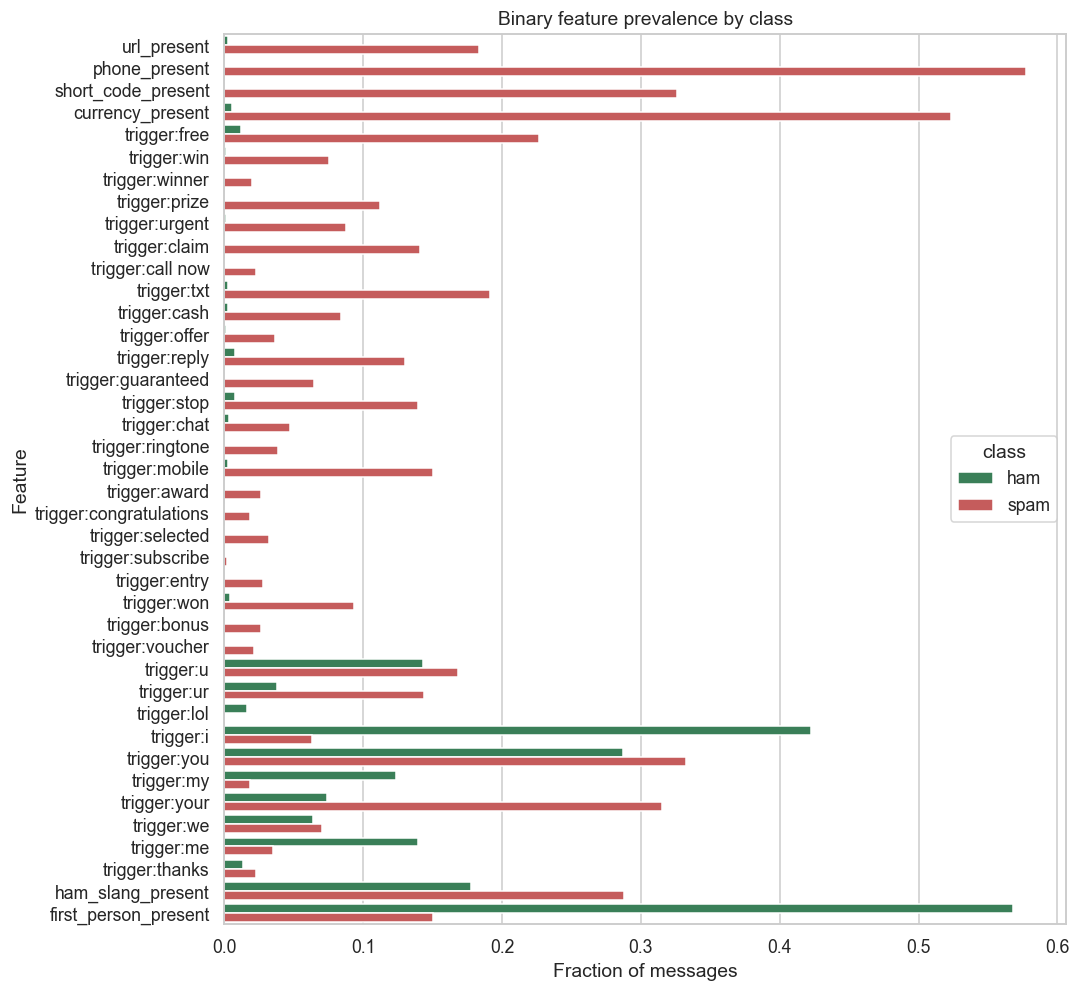

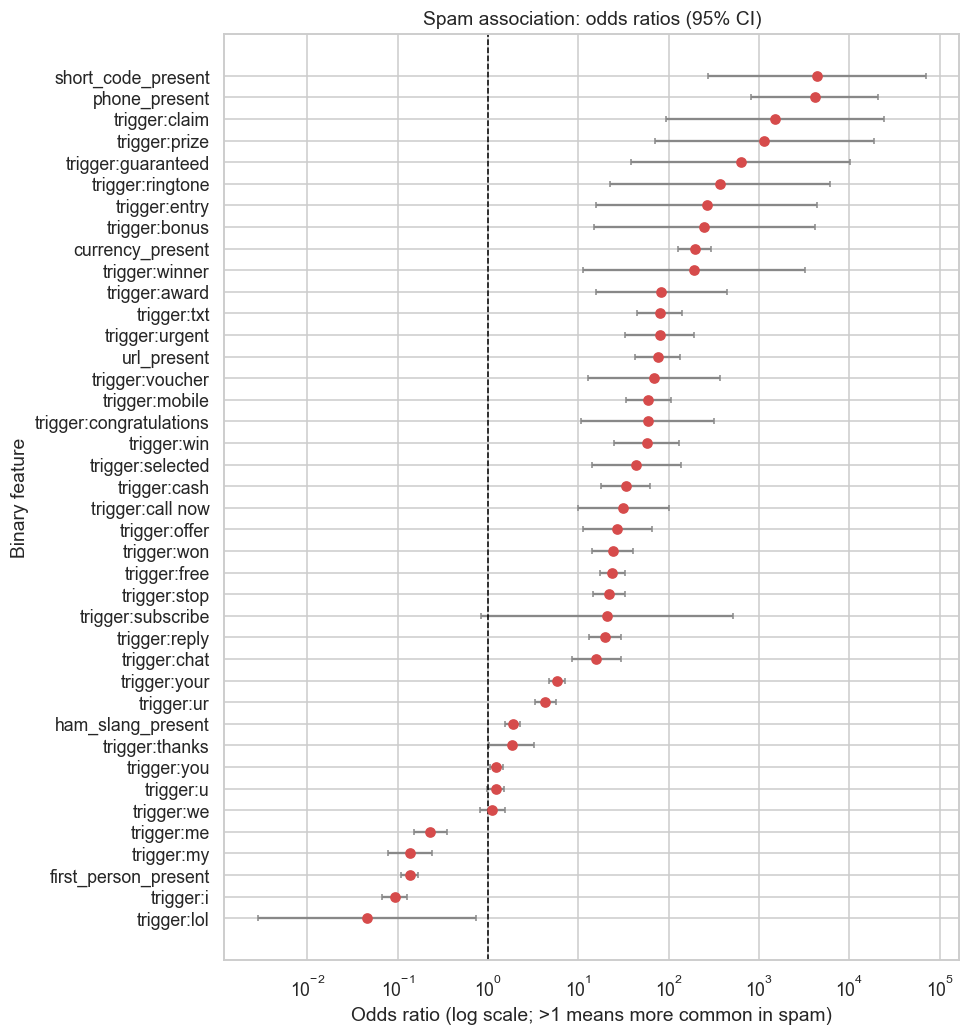

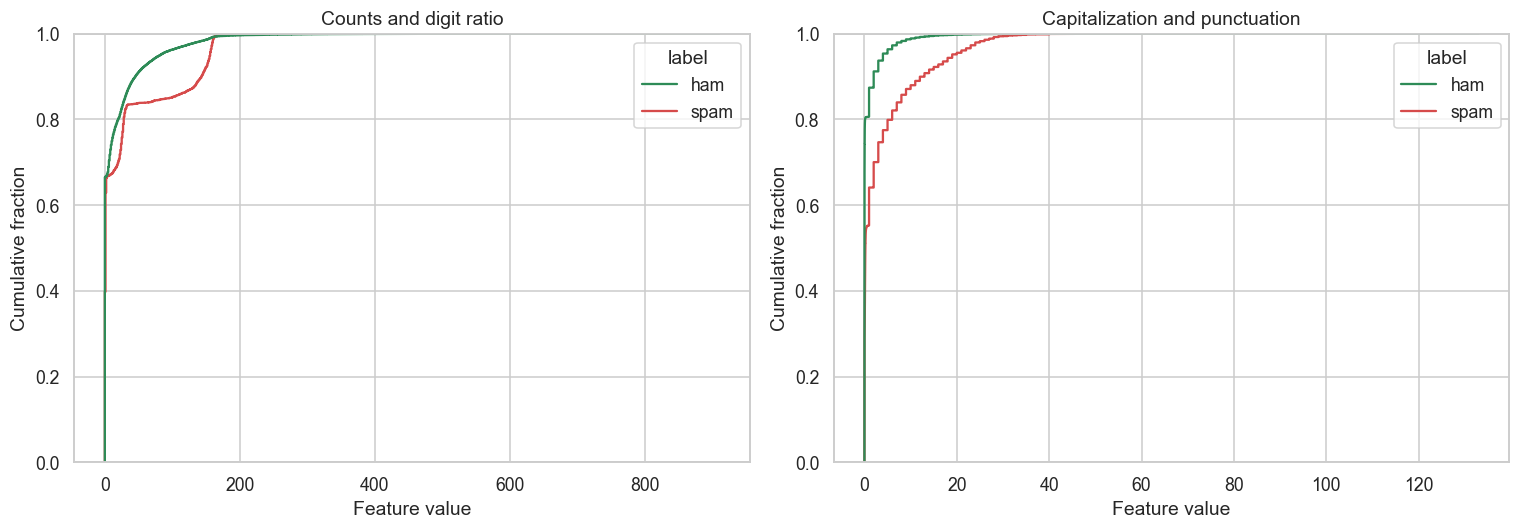

In [30]:

# 1. Import statistical tools

from scipy.stats import fisher_exact, mannwhitneyu
from statsmodels.stats.multitest import multipletests

# Identify spam messages
is_spam = (df['label'] == 'spam').to_numpy()


# 2. Statistical analysis of binary features

binary_rows = []

for col in BINARY_FEATURES:

    # Count feature presence and absence in spam and ham
    a = ((df['label'] == 'spam') & (df[col] == 1)).sum()
    b = ((df['label'] == 'spam') & (df[col] == 0)).sum()
    c = ((df['label'] == 'ham') & (df[col] == 1)).sum()
    d = ((df['label'] == 'ham') & (df[col] == 0)).sum()

    # Apply Haldane correction
    a1 = a + 0.5
    b1 = b + 0.5
    c1 = c + 0.5
    d1 = d + 0.5

    # Calculate odds ratio and confidence interval
    odds = (a1 * d1) / (b1 * c1)

    se = math.sqrt(
        1/a1 + 1/b1 + 1/c1 + 1/d1
    )

    lower = math.exp(math.log(odds) - 1.96 * se)
    upper = math.exp(math.log(odds) + 1.96 * se)

    # Fisher's exact test
    p = fisher_exact(
        [[a, b], [c, d]],
        alternative='two-sided'
    ).pvalue

    # Store results
    binary_rows.append({
        'feature': col,
        'spam_rate': a / (a + b),
        'ham_rate': c / (c + d),
        'spam_n': a,
        'ham_n': c,
        'odds_ratio': odds,
        'or_low': lower,
        'or_high': upper,
        'p_value': p
    })


# Create binary statistics table
binary_stats = pd.DataFrame(binary_rows)

# Correct p-values for multiple testing
binary_stats['q_value'] = multipletests(
    binary_stats['p_value'],
    method='fdr_bh'
)[1]


# 3. Statistical analysis of numerical features

numeric_rows = []

for col in NUMERIC_FEATURES:

    # Separate spam and ham values
    ham = df.loc[df['label'] == 'ham', col].to_numpy()
    spam = df.loc[df['label'] == 'spam', col].to_numpy()

    # Mann-Whitney U test
    test = mannwhitneyu(
        spam,
        ham,
        alternative='two-sided'
    )

    # Calculate AUC
    auc = roc_auc_score(is_spam, df[col])

    # Store results
    numeric_rows.append({
        'feature': col,
        'ham_median': np.median(ham),
        'spam_median': np.median(spam),
        'AUC_spam_higher': auc,
        'p_value': test.pvalue
    })


# Create numerical statistics table
numeric_stats = pd.DataFrame(numeric_rows)

# Correct p-values for multiple testing
numeric_stats['q_value'] = multipletests(
    numeric_stats['p_value'],
    method='fdr_bh'
)[1]


# 4. Display statistical results

display(
    binary_stats.sort_values(
        'odds_ratio',
        ascending=False
    ).round(4)
)

display(
    numeric_stats.sort_values(
        'AUC_spam_higher',
        ascending=False
    ).round(4)
)


# 5. Display important findings

significant_count = (
    binary_stats['q_value'] < CONFIG['feature_q_threshold']
).sum()

total_features = len(binary_stats)

largest_feature = binary_stats.loc[
    binary_stats['odds_ratio'].idxmax()
]

char_auc = roc_auc_score(
    is_spam,
    df['char_length']
)

ham_median = df.loc[
    df['label'] == 'ham', 'char_length'
].median()

spam_median = df.loc[
    df['label'] == 'spam', 'char_length'
].median()


display(Markdown(
    f"**Key takeaway — binary patterns:** "
    f"{significant_count} of {total_features} features have "
    f"FDR-adjusted q < {CONFIG['feature_q_threshold']:.2f}. "
    f"Largest odds ratio: **{largest_feature['feature']}**, "
    f"OR {largest_feature['odds_ratio']:.2f} "
    f"(95% CI {largest_feature['or_low']:.2f}–{largest_feature['or_high']:.2f})."
))

display(Markdown(
    f"**Key takeaway — numeric patterns:** "
    f"Median character length is {ham_median:.0f} for ham "
    f"and {spam_median:.0f} for spam; "
    f"character-length AUC = {char_auc:.3f}."
))


# 6. Plot binary feature prevalence

plot_rates = binary_stats.melt(
    id_vars='feature',
    value_vars=['ham_rate', 'spam_rate'],
    var_name='class',
    value_name='prevalence'
)

plot_rates['class'] = plot_rates['class'].map({
    'ham_rate': 'ham',
    'spam_rate': 'spam'
})

fig, ax = plt.subplots(
    figsize=(10, max(5, len(BINARY_FEATURES) * 0.23))
)

sns.barplot(
    data=plot_rates,
    y='feature',
    x='prevalence',
    hue='class',
    hue_order=['ham', 'spam'],
    palette=PALETTE,
    ax=ax
)

ax.set_title('Binary feature prevalence by class')
ax.set_xlabel('Fraction of messages')
ax.set_ylabel('Feature')

plt.tight_layout()
plt.show()


# 7. Plot odds ratios with confidence intervals

forest = binary_stats.sort_values(
    'odds_ratio'
).reset_index(drop=True)

fig, ax = plt.subplots(
    figsize=(9, max(5, len(forest) * 0.24))
)

y = np.arange(len(forest))

ax.errorbar(
    forest['odds_ratio'],
    y,
    xerr=[
        forest['odds_ratio'] - forest['or_low'],
        forest['or_high'] - forest['odds_ratio']
    ],
    fmt='o',
    color=SPAM,
    ecolor='#888888',
    capsize=2
)

ax.axvline(1, color='black', linestyle='--', linewidth=1)
ax.set_xscale('log')
ax.set_yticks(y, forest['feature'])

ax.set_title('Spam association: odds ratios (95% CI)')
ax.set_xlabel('Odds ratio (log scale; >1 means more common in spam)')
ax.set_ylabel('Binary feature')

plt.tight_layout()
plt.show()


# 8. Plot numerical feature distributions

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

feature_groups = [
    NUMERIC_FEATURES[:6],
    NUMERIC_FEATURES[6:]
]

titles = [
    'Counts and digit ratio',
    'Capitalization and punctuation'
]

for i in range(2):

    long = df.melt(
        id_vars='label',
        value_vars=feature_groups[i],
        var_name='feature',
        value_name='value'
    )

    sns.ecdfplot(
        data=long,
        x='value',
        hue='label',
        hue_order=['ham', 'spam'],
        palette=PALETTE,
        ax=axes[i]
    )

    axes[i].set_title(titles[i])
    axes[i].set_xlabel('Feature value')
    axes[i].set_ylabel('Cumulative fraction')

plt.tight_layout()
plt.show()


## 9. Word and phrase analysis

Create adjacent word n-grams before stopword filtering so phrases such as “call me now” remain intact. Report frequent n-grams before and after filtering n-grams made exclusively of stopwords. Rank distinctive terms using Monroe-style log odds with an informative Dirichlet prior and a minimum document-frequency cutoff. The chi-square ranking is vectorized across terms.

Top words (all terms, spam)


,ngram,count
0,<num>,837
1,to,599
2,<money>,423
3,<phone>,405
4,a,347
5,call,322
6,you,262
7,your,242
8,<shortcode>,230
9,free,197


Top words (stopword-only phrases removed, spam)


,ngram,count
0,<num>,837
1,<money>,423
2,<phone>,405
3,call,322
4,<shortcode>,230
5,free,197
6,u,147
7,txt,136
8,<url>,128
9,ur,119


Top words (stopword-only phrases removed, ham)


,ngram,count
0,u,925
1,<num>,797
2,get,301
3,ok,255
4,go,248
5,:),233
6,got,228
7,know,226
8,like,224
9,good,217


... (10 outputs left out)

Top trigrams (stopword-only phrases removed, ham)


,ngram,count
0,i want to,29
1,let me know,26
2,i love you,25
3,i miss you,25
4,have a great,24
5,hope you are,19
6,give me a,19
7,<num> <num> <num>,18
8,you want to,16
9,i need you,16


,term,spam_df,ham_df,log_odds,z_score,chi2,chi2_p
19,<money>,335,25,3.793,18.417,2110.574,0.0
1060,call,287,177,1.689,17.693,1019.025,0.0
54,<num>,413,550,0.922,14.168,799.128,0.0
2012,free,150,55,2.203,13.999,681.029,0.0
234,<url>,120,15,3.273,12.000,711.583,0.0
6048,txt,126,13,3.464,11.948,766.848,0.0
5321,stop,93,33,2.234,11.042,427.464,0.0
3752,mobile,100,13,3.233,11.010,589.494,0.0
4800,reply,85,34,2.114,10.433,372.905,0.0
5484,text,92,66,1.531,9.502,297.763,0.0


,term,spam_df,ham_df,log_odds,z_score,chi2,chi2_p
2628,i,44,1566,-2.359,-15.707,142.878,0.000
3586,me,23,630,-2.094,-9.998,49.074,0.000
2880,in,63,687,-1.188,-9.075,12.152,0.000
3865,my,11,561,-2.692,-9.066,59.410,0.000
3057,it,25,471,-1.726,-8.488,25.882,0.000
5522,that,23,424,-1.704,-8.032,22.684,0.000
5145,so,19,392,-1.814,-7.802,23.872,0.000
6869,you,214,1248,-0.568,-7.703,5.350,0.021
4059,not,22,369,-1.610,-7.400,17.372,0.000
989,but,6,395,-2.931,-7.359,45.037,0.000


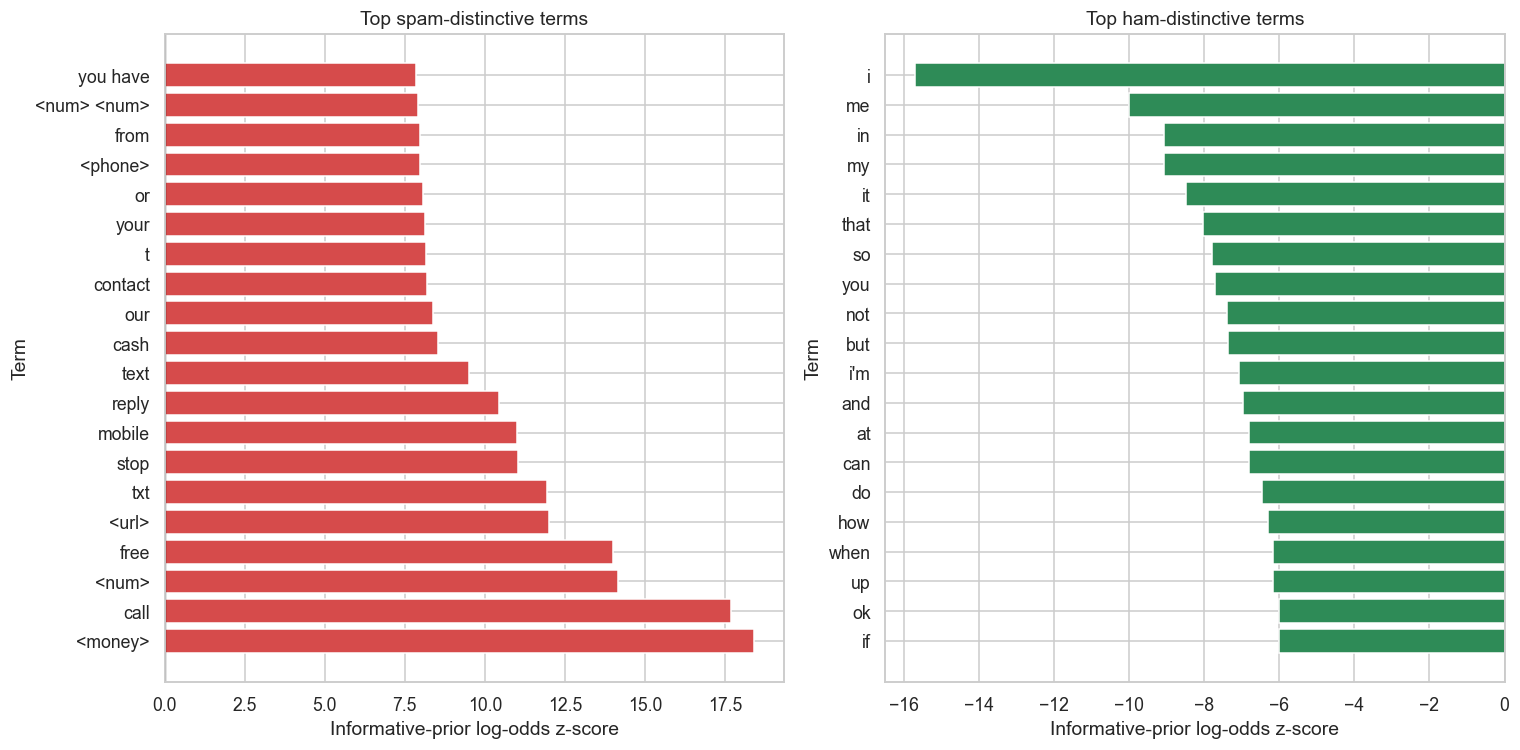

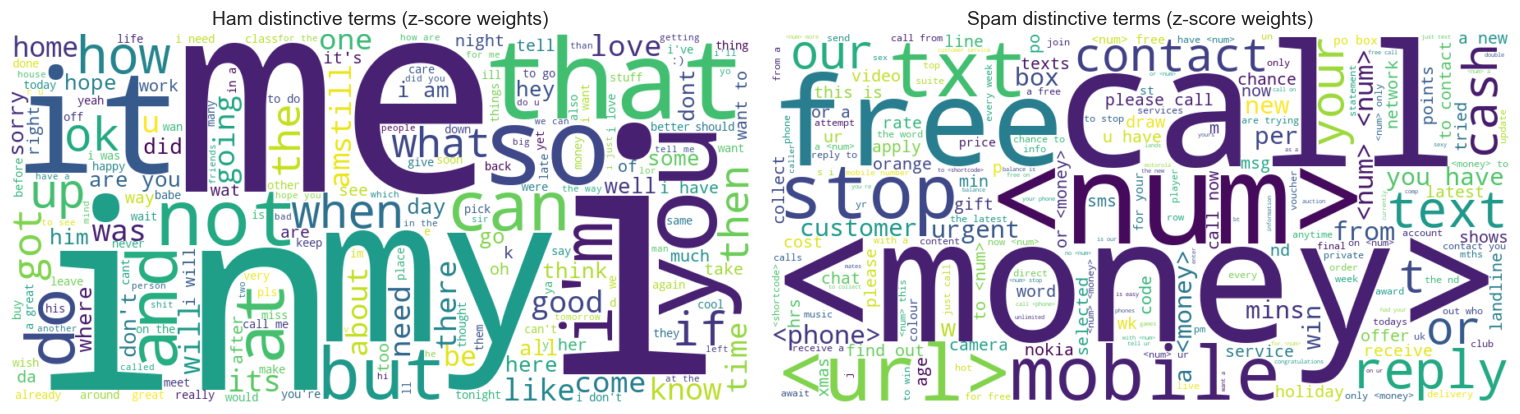

**Key takeaway — vocabulary:** The strongest spam term is **<money>** (z = 18.4); the strongest ham term is **i** (z = -15.7). These scores compare class-specific document rates with pooled prior smoothing.

In [31]:

import nltk
from nltk.corpus import stopwords
from sklearn.feature_extraction.text import CountVectorizer, ENGLISH_STOP_WORDS
from sklearn.feature_selection import chi2
from wordcloud import WordCloud

# Load English stopwords
try:
    STOPWORDS = set(stopwords.words('english'))
except LookupError:
    try:
        nltk.download('stopwords', quiet=True)
        STOPWORDS = set(stopwords.words('english'))
    except Exception:
        STOPWORDS = set(ENGLISH_STOP_WORDS)
        print('NLTK corpus unavailable; used scikit-learn English stopword fallback.')

# Tokenize normalized messages
TOKEN_RE = re.compile(
    r'<(?:url|phone|shortcode|money|num)>|[a-z]+(?:\'[a-z]+)?|[:;=8][-^]?[)(DPp]'
)

df['norm_tokens'] = df['normalized_text'].map(TOKEN_RE.findall)


# Generate n-gram frequency tables
def ngram_table(label, n, remove_stop_only=False, top=15):
    counts = {}

    for tokens in df.loc[df.label == label, 'norm_tokens']:
        for gram in zip(*(tokens[i:] for i in range(n))):
            if remove_stop_only and all(word in STOPWORDS for word in gram):
                continue

            counts[gram] = counts.get(gram, 0) + 1

    result = pd.DataFrame([
        {'ngram': ' '.join(key), 'count': value}
        for key, value in counts.items()
    ])

    return (
        result.sort_values('count', ascending=False)
              .head(top)
              .reset_index(drop=True)
    )


# Display frequent words, bigrams and trigrams
for n, name in [(1, 'words'), (2, 'bigrams'), (3, 'trigrams')]:
    print(f'Top {name} (all terms, spam)')
    display(ngram_table('spam', n, False))

    print(f'Top {name} (stopword-only phrases removed, spam)')
    display(ngram_table('spam', n, True))

    print(f'Top {name} (stopword-only phrases removed, ham)')
    display(ngram_table('ham', n, True))


# Create binary document-term matrix
vectorizer = CountVectorizer(
    tokenizer=lambda s: s.split(),
    token_pattern=None,
    lowercase=False,
    ngram_range=(1, 2),
    min_df=CONFIG['min_doc_freq'],
    binary=True
)

X_words = vectorizer.fit_transform(
    df.normalized_text.map(lambda s: ' '.join(TOKEN_RE.findall(s)))
)

terms = np.asarray(vectorizer.get_feature_names_out())

# Separate spam and ham messages
spam_mask = (df.label == 'spam').to_numpy()
ham_mask = ~spam_mask

spam_doc = np.asarray(X_words[spam_mask].sum(axis=0)).ravel()
ham_doc = np.asarray(X_words[ham_mask].sum(axis=0)).ravel()


# Calculate informative-prior log-odds
pooled = spam_doc + ham_doc
alpha = 100 * pooled / pooled.sum()

spam_total = spam_doc.sum()
ham_total = ham_doc.sum()
alpha_total = alpha.sum()

log_odds = (
    np.log(
        (spam_doc + alpha) /
        (spam_total - spam_doc + alpha_total - alpha)
    )
    -
    np.log(
        (ham_doc + alpha) /
        (ham_total - ham_doc + alpha_total - alpha)
    )
)

variance = 1 / (spam_doc + alpha) + 1 / (ham_doc + alpha)
z_score = log_odds / np.sqrt(variance)


# Calculate chi-square scores
chi_scores, chi_p = chi2(X_words, spam_mask.astype(int))


# Combine vocabulary statistics
distinctive = pd.DataFrame({
    'term': terms,
    'spam_df': spam_doc,
    'ham_df': ham_doc,
    'log_odds': log_odds,
    'z_score': z_score,
    'chi2': chi_scores,
    'chi2_p': chi_p
})

distinctive = distinctive[
    (distinctive.spam_df + distinctive.ham_df) >= CONFIG['min_doc_freq']
]

# Display top spam and ham terms
display(
    distinctive.sort_values('z_score', ascending=False)
               .head(20)
               .round(3)
)

display(
    distinctive.sort_values('z_score')
               .head(20)
               .round(3)
)


# Plot distinctive vocabulary
fig, axes = plt.subplots(1, 2, figsize=(14, 7))

spam_terms = distinctive.nlargest(20, 'z_score')
ham_terms = distinctive.nsmallest(20, 'z_score').sort_values(
    'z_score', ascending=False
)

plot_data = [
    (axes[0], spam_terms, 'Top spam-distinctive terms', SPAM),
    (axes[1], ham_terms, 'Top ham-distinctive terms', HAM)
]

for ax, subset, title, color in plot_data:
    ax.barh(subset.term, subset.z_score, color=color)
    ax.set(
        title=title,
        xlabel='Informative-prior log-odds z-score',
        ylabel='Term'
    )
    ax.axvline(0, color='black', lw=0.8)

plt.tight_layout()
plt.show()


# Generate word clouds
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for ax, label in zip(axes, ['ham', 'spam']):
    score = distinctive.set_index('term').z_score

    if label == 'spam':
        weights = score.clip(lower=0).to_dict()
    else:
        weights = (-score).clip(lower=0).to_dict()

    weights = {
        key: float(value)
        for key, value in weights.items()
        if value > 0
    }

    cloud = WordCloud(
        width=900,
        height=450,
        background_color='white',
        collocations=False,
        random_state=CONFIG['seed']
    ).generate_from_frequencies(weights)

    ax.imshow(cloud, interpolation='bilinear')
    ax.axis('off')
    ax.set_title(f'{label.title()} distinctive terms (z-score weights)')

plt.tight_layout()
plt.show()


# Display key findings
display(Markdown(
    f"**Key takeaway — vocabulary:** "
    f"The strongest spam term is **{distinctive.iloc[distinctive.z_score.argmax()].term}** "
    f"(z = {distinctive.z_score.max():.1f}); "
    f"the strongest ham term is **{distinctive.iloc[distinctive.z_score.argmin()].term}** "
    f"(z = {distinctive.z_score.min():.1f}). "
    f"These scores compare class-specific document rates with pooled prior smoothing."
))


## 10. Spam families

Use TF-IDF and six-cluster KMeans to group spam messages into data-driven families. Label each cluster by its leading terms, show representative messages and sizes, then compare family-level prevalence of core pattern features. These groups summarize vocabulary overlap rather than verified message intent.

Family 0: 155 messages; top terms: the, you, a, num, your, to


,message_raw
0,"XXXMobileMovieClub: To use your credit, click ..."
1,Thanks for your subscription to Ringtone UK yo...
2,SMS. ac Sptv: The New Jersey Devils and the De...


Family 1: 73 messages; top terms: num, money, u, is, this is, to


,message_raw
0,URGENT! Your Mobile No. was awarded £2000 Bonu...
1,Congratulations ur awarded 500 of CD vouchers ...
2,100 dating service cal;l 09064012103 box334sk38ch


Family 2: 94 messages; top terms: you have, call, a, num, you, call phone


,message_raw
0,WINNER!! As a valued network customer you have...
1,Please call our customer service representativ...
2,GENT! We are trying to contact you. Last weeke...


... (3 outputs left out)

,message_raw
0,PRIVATE! Your 2004 Account Statement for 07742...
1,PRIVATE! Your 2003 Account Statement for 07815...
2,PRIVATE! Your 2003 Account Statement for 07753...


Family 5: 260 messages; top terms: num, to, shortcode, money, to shortcode, stop


,message_raw
0,Free entry in 2 a wkly comp to win FA Cup fina...
1,FreeMsg Hey there darling it's been 3 week's n...
2,"SIX chances to win CASH! From 100 to 20,000 po..."


,family_id,size,share_of_spam,label_terms
5,5,260,0.398,"num, to, shortcode, money, to shortcode, stop"
0,0,155,0.237,"the, you, a, num, your, to"
2,2,94,0.144,"you have, call, a, num, you, call phone"
1,1,73,0.112,"num, money, u, is, this is, to"
3,3,55,0.084,"free, mins, on, call, phone, on phone"
4,4,16,0.025,"num, num num, num account, account, account st..."


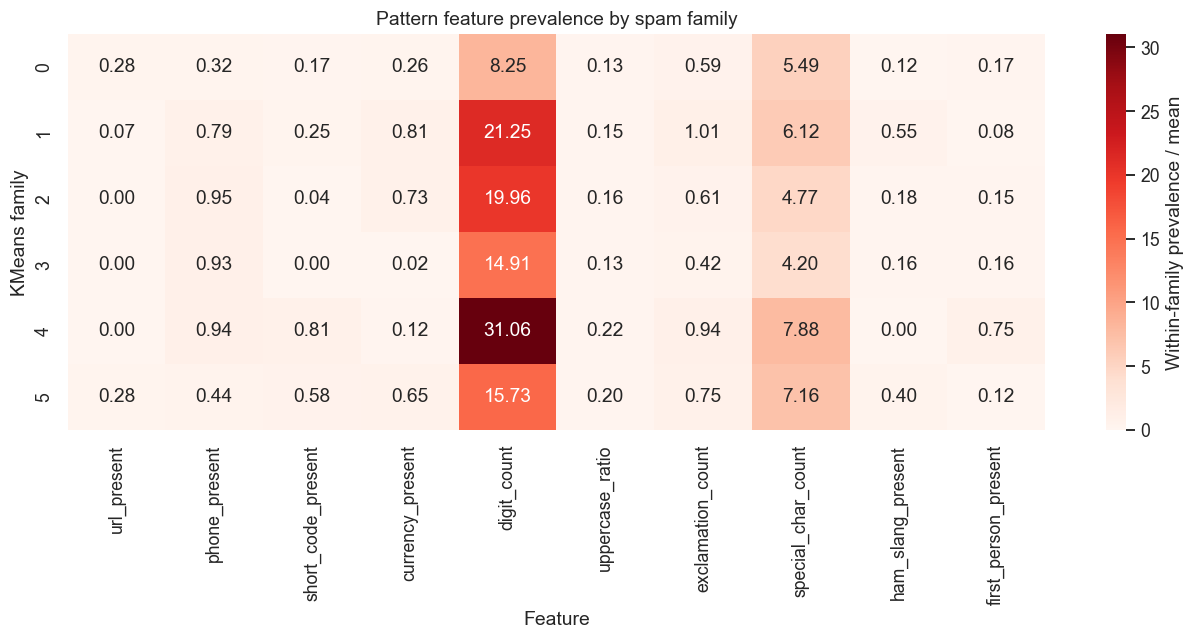

**Key takeaway — spam families:** The largest cluster contains 260 of 653 spam messages (39.8%); inspect its top terms and examples above before assigning a semantic label.

In [32]:

from sklearn.cluster import KMeans
from sklearn.feature_extraction.text import TfidfVectorizer

# Select spam messages
spam_rows = df.index[df.label == 'spam']

# Convert spam messages into TF-IDF features
family_vectorizer = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=6000,
    token_pattern=r'(?u)\b\w+\b'
)

X_spam_tfidf = family_vectorizer.fit_transform(
    df.loc[spam_rows, 'normalized_text']
)

# Determine the number of clusters
k = min(
    CONFIG['n_families'],
    max(2, len(spam_rows) // 20)
)

# Apply K-Means clustering
kmeans = KMeans(
    n_clusters=k,
    random_state=CONFIG['seed'],
    n_init=10
)

family_id = kmeans.fit_predict(X_spam_tfidf)

# Store cluster assignments in the original DataFrame
df['family_id'] = pd.Series(
    pd.NA,
    index=df.index,
    dtype='Int64'
)

df.loc[spam_rows, 'family_id'] = family_id

# Get vocabulary terms
terms_family = np.asarray(
    family_vectorizer.get_feature_names_out()
)

# Summarize each spam family
family_info = []

for fid in range(k):
    members = df[
        (df.label == 'spam') &
        (df.family_id == fid)
    ]

    top_idx = np.argsort(
        kmeans.cluster_centers_[fid]
    )[::-1][:6]

    top_terms = ', '.join(terms_family[top_idx])

    family_info.append({
        'family_id': fid,
        'size': len(members),
        'share_of_spam': len(members) / len(spam_rows),
        'label_terms': top_terms
    })

    print(
        f"Family {fid}: {len(members)} messages; "
        f"top terms: {top_terms}"
    )

    display(
        members[['message_raw']]
        .head(3)
        .reset_index(drop=True)
    )

# Display family summary
family_info = pd.DataFrame(family_info).sort_values(
    'size',
    ascending=False
)

display(family_info.round(3))


# Compare features across spam families
family_features = [
    'url_present',
    'phone_present',
    'short_code_present',
    'currency_present',
    'digit_count',
    'uppercase_ratio',
    'exclamation_count',
    'special_char_count',
    'ham_slang_present',
    'first_person_present'
]

family_means = (
    df[df.label == 'spam']
    .groupby('family_id')[family_features]
    .mean()
)

# Plot feature prevalence heatmap
fig, ax = plt.subplots(figsize=(12, 6))

sns.heatmap(
    family_means,
    annot=True,
    fmt='.2f',
    cmap='Reds',
    vmin=0,
    ax=ax,
    cbar_kws={'label': 'Within-family prevalence / mean'}
)

ax.set(
    title='Pattern feature prevalence by spam family',
    xlabel='Feature',
    ylabel='KMeans family'
)

plt.tight_layout()
plt.show()


# Display key finding
display(Markdown(
    f"**Key takeaway — spam families:** "
    f"The largest cluster contains "
    f"{int(family_info.iloc[0]['size'])} of {len(spam_rows)} "
    f"spam messages "
    f"({family_info.iloc[0].share_of_spam:.1%}); "
    f"inspect its top terms and examples above before assigning "
    f"a semantic label."
))


## 11. Association rule mining

Mine frequent itemsets within spam messages, combining salient normalized tokens, binary engineered features, and the top distinctive terms from section 9. For every candidate pattern, compute support in the full corpus, confidence within spam, confidence within ham, and lift (`P(spam | pattern) / P(spam)`). The mlxtend `association_rules` call includes compatibility handling for releases that require `num_itemsets`.

,pattern,support,spam_confidence,ham_confidence,lift,rank_score
1,feature:phone,0.0731,0.9974,0.0026,7.8979,0.5773
16,term:<phone>,0.0725,0.9973,0.0027,7.8977,0.5727
0,feature:currency,0.0710,0.9319,0.0681,7.3794,0.5237
15,term:<money>,0.0696,0.9306,0.0694,7.3689,0.5130
20,term:call,0.0897,0.6185,0.3815,4.8981,0.4395
90,feature:phone + term:call,0.0536,1.0000,0.0000,7.9188,0.4242
192,term:<phone> + term:call,0.0536,1.0000,0.0000,7.9188,0.4242
87,feature:phone + term:<num>,0.0483,1.0000,0.0000,7.9188,0.3828
176,term:<num> + term:<phone>,0.0478,1.0000,0.0000,7.9188,0.3783
52,feature:currency + term:<num>,0.0441,0.9561,0.0439,7.5715,0.3338


**Key takeaway — association rules:** 162 nonredundant patterns passed the thresholds; the top-ranked pattern is `feature:phone` (support 0.073, spam confidence 0.997, lift 7.90).

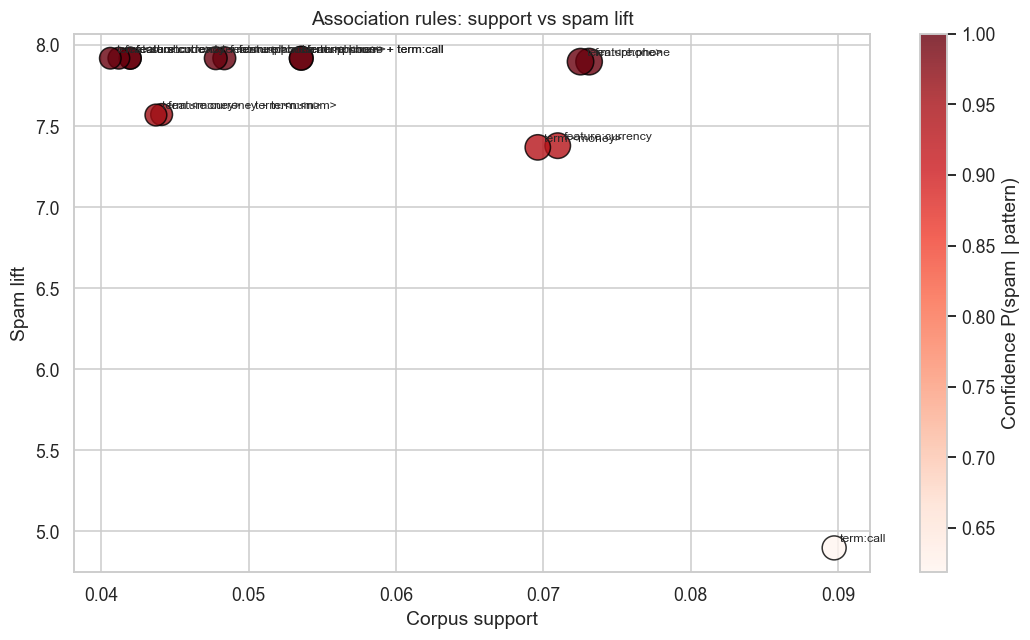

In [33]:

from mlxtend.preprocessing import TransactionEncoder
from mlxtend.frequent_patterns import apriori, association_rules

# Select the 30 most spam-distinctive terms
top_distinctive = set(
    distinctive.nlargest(30, 'z_score').term
)

# Make feature names easier to read
item_names = {
    col: col.replace('trigger:', 'trigger ')
           .replace('_present', '')
           .replace('_', ' ')
    for col in BINARY_FEATURES
}

# Create transactions for every message
transactions = []

for idx, row in df.iterrows():
    items = set()

    # Add binary features present in the message
    for col in BINARY_FEATURES:
        if row[col]:
            items.add(f"feature:{item_names[col]}")

    # Add selected distinctive terms and placeholders
    for token in set(row.norm_tokens):
        if (
            token in {'<url>', '<phone>', '<shortcode>', '<money>', '<num>'}
            or token in top_distinctive
        ):
            items.add(f'term:{token}')

    transactions.append(items)


# Convert transactions into a binary basket
encoder = TransactionEncoder()

basket = pd.DataFrame(
    encoder.fit(transactions).transform(transactions),
    columns=encoder.columns_,
    index=df.index
)

# Select spam messages
spam_basket = basket.loc[df.label == 'spam']

# Find frequent itemsets using Apriori
freq = apriori(
    spam_basket,
    min_support=CONFIG['association_min_support'],
    use_colnames=True,
    max_len=3
)

# Generate association rules within spam
if not freq.empty:
    try:
        within_spam_rules = association_rules(
            freq,
            metric='confidence',
            min_threshold=0.0,
            num_itemsets=len(spam_basket)
        )
    except TypeError:
        within_spam_rules = association_rules(
            freq,
            metric='confidence',
            min_threshold=0.0
        )
else:
    within_spam_rules = pd.DataFrame()


# Evaluate frequent patterns across the full dataset
base_spam_rate = (df.label == 'spam').mean()
candidates = []

for itemset in freq.itemsets if not freq.empty else []:

    mask = basket[list(itemset)].all(axis=1)

    support = float(mask.mean())

    spam_conf = float(
        (df.loc[mask, 'label'] == 'spam').mean()
    )

    ham_conf = float(
        (df.loc[mask, 'label'] == 'ham').mean()
    )

    if (
        support >= CONFIG['association_min_support']
        and spam_conf >= CONFIG['association_min_spam_confidence']
    ):
        candidates.append({
            'pattern': ' + '.join(sorted(itemset)),
            'items': frozenset(itemset),
            'support': support,
            'spam_confidence': spam_conf,
            'ham_confidence': ham_conf,
            'lift': spam_conf / base_spam_rate,
            'rank_score': support * (spam_conf / base_spam_rate)
        })


# Create the association rule table
rules_df = pd.DataFrame(candidates)

if not rules_df.empty:

    # Remove redundant patterns when a simpler subset
    # has equal or higher spam confidence
    keep = []

    for _, rule in rules_df.iterrows():
        redundant = any(
            other['items'] < rule['items']
            and other['spam_confidence'] >= rule['spam_confidence']
            for _, other in rules_df.iterrows()
        )

        keep.append(not redundant)

    rules_df = (
        rules_df.loc[keep]
        .drop_duplicates('pattern')
        .sort_values('rank_score', ascending=False)
    )

    display(
        rules_df[
            [
                'pattern',
                'support',
                'spam_confidence',
                'ham_confidence',
                'lift',
                'rank_score'
            ]
        ].head(15).round(4)
    )

    display(Markdown(
        f"**Key takeaway — association rules:** "
        f"{len(rules_df)} nonredundant patterns passed the thresholds; "
        f"the top-ranked pattern is `{rules_df.iloc[0].pattern}` "
        f"(support {rules_df.iloc[0].support:.3f}, "
        f"spam confidence {rules_df.iloc[0].spam_confidence:.3f}, "
        f"lift {rules_df.iloc[0].lift:.2f})."
    ))

else:
    print('No rules met the configured support and confidence thresholds.')

    display(Markdown(
        '**Key takeaway — association rules:** No pattern met both '
        'configured thresholds; the table remains empty rather than '
        'reporting unstable low-support rules.'
    ))


# Visualize the top association patterns
if not rules_df.empty:

    shown = rules_df.head(15)

    fig, ax = plt.subplots(figsize=(10, 6))

    points = ax.scatter(
        shown.support,
        shown.lift,
        c=shown.spam_confidence,
        cmap='Reds',
        s=70 + shown.rank_score * 400,
        edgecolor='black',
        alpha=0.8
    )

    for _, rule in shown.iterrows():
        ax.annotate(
            rule.pattern[:32],
            (rule.support, rule.lift),
            xytext=(4, 4),
            textcoords='offset points',
            fontsize=8
        )

    ax.set(
        title='Association rules: support vs spam lift',
        xlabel='Corpus support',
        ylabel='Spam lift'
    )

    fig.colorbar(
        points,
        ax=ax,
        label='Confidence P(spam | pattern)'
    )

    plt.tight_layout()
    plt.show()


## 12. Interpretation and findings

The numbered findings below are generated from the executed statistics, with figure/table references for context. Treat small subgroup rates and correlated indicators cautiously; the same SMS can contribute to several patterns.

In [34]:

# Helper functions
def rate(col, label):
    return float(df.loc[df.label == label, col].mean())


def pct(value):
    return f'{100 * value:.1f}%'


# Get important binary feature statistics
binary_table = binary_stats.set_index('feature')

url_row = binary_table.loc['url_present']
phone_row = binary_table.loc['phone_present']
money_row = binary_table.loc['currency_present']

if 'trigger:call now' in binary_table.index:
    exclaim_row = binary_table.loc['trigger:call now']
else:
    exclaim_row = binary_stats.iloc[0]


# Get message length statistics
length_table = length_stats.set_index('measure')

length_char = length_table.loc['char_length']
length_word = length_table.loc['word_length']


# Identify the strongest binary feature
strong_binary = (
    binary_stats.sort_values('odds_ratio', ascending=False)
    .head(1)
    .iloc[0]
)

# Get top association rules
top_rules = (
    rules_df.head(3)
    if not rules_df.empty
    else pd.DataFrame()
)


# Prepare key findings
findings = [
    f"**Length:** Median characters are {df.loc[df.label=='ham','char_length'].median():.0f} for ham vs {df.loc[df.label=='spam','char_length'].median():.0f} for spam (AUC {length_char.AUC_spam_longer:.3f}, q={numeric_stats.set_index('feature').loc['char_length','q_value']:.2g}; Figure 5).",

    f"**URLs:** URL presence is {pct(url_row.spam_rate)} in spam vs {pct(url_row.ham_rate)} in ham (OR {url_row.odds_ratio:.1f}, 95% CI {url_row.or_low:.1f}–{url_row.or_high:.1f}; Table 8 / Figure 8).",

    f"**Numbers and phone patterns:** Phone-like presence is {pct(phone_row.spam_rate)} vs {pct(phone_row.ham_rate)} (OR {phone_row.odds_ratio:.1f}); short-code prevalence is {pct(rate('short_code_present','spam'))} vs {pct(rate('short_code_present','ham'))} (Table 8).",

    f"**Currency:** Currency amount prevalence is {pct(money_row.spam_rate)} vs {pct(money_row.ham_rate)} (OR {money_row.odds_ratio:.1f}; Table 8).",

    f"**Capitalization and punctuation:** Median uppercase ratio is {df.loc[df.label=='spam','uppercase_ratio'].median():.3f} in spam vs {df.loc[df.label=='ham','uppercase_ratio'].median():.3f} in ham; median exclamation counts are {df.loc[df.label=='spam','exclamation_count'].median():.0f} vs {df.loc[df.label=='ham','exclamation_count'].median():.0f} (Figure 8 ECDFs).",

    f"**Trigger language:** The top informative-prior spam term is `{distinctive.iloc[distinctive.z_score.argmax()].term}` (z={distinctive.z_score.max():.1f}); common trigger `free` appears in {pct(rate('trigger:free','spam'))} vs {pct(rate('trigger:free','ham'))} (Section 9 / Table 8).",

    f"**Calls to action:** `call now` appears in {pct(rate('trigger:call now','spam'))} vs {pct(rate('trigger:call now','ham'))} (OR {binary_table.loc['trigger:call now','odds_ratio']:.1f}; Table 8).",

    f"**Ham-style language:** Slang indicator prevalence is {pct(rate('ham_slang_present','ham'))} in ham vs {pct(rate('ham_slang_present','spam'))} in spam; pronouns are retained in the phrase analysis (Table 8).",

    f"**Spam families:** KMeans grouped spam into {k} families; the largest contains {int(family_info.iloc[0]['size'])} messages ({family_info.iloc[0].share_of_spam:.1%}), with top terms `{family_info.iloc[0]['label_terms']}` (Figure 10 heatmap).",

    (
        f"**Association rules:** {len(rules_df)} rules passed the support/confidence thresholds after redundancy filtering; the highest-ranked pattern is `{rules_df.iloc[0].pattern}` (support {rules_df.iloc[0].support:.3f}, lift {rules_df.iloc[0].lift:.2f}; Figure 11)."
        if not rules_df.empty
        else "**Association rules:** No candidate passed configured thresholds; see Section 11 and lower thresholds only with careful validation."
    )
]


# Display findings one by one
for i, finding in enumerate(findings, 1):
    display(Markdown(f'{i}. {finding}'))


# Create final comparison summary
summary_rows = []

for key, interpretation in [
    ('url_present', 'external link'),
    ('phone_present', 'phone/callback contact'),
    ('short_code_present', 'premium or service short code'),
    ('currency_present', 'money or prize framing'),
    ('trigger:free', 'offer framing'),
    ('trigger:call now', 'direct call to action'),
    ('ham_slang_present', 'informal ham-style language')
]:

    row = binary_table.loc[key]

    summary_rows.append({
        'pattern': key,
        'spam_rate': row.spam_rate,
        'ham_rate': row.ham_rate,
        'odds_ratio': row.odds_ratio,
        'interpretation': interpretation
    })


findings_summary = (
    pd.DataFrame(summary_rows)
    .sort_values('odds_ratio', ascending=False)
)

display(findings_summary.round(3))


1. **Length:** Median characters are 53 for ham vs 148 for spam (AUC 0.873, q=3.4e-209; Figure 5).

2. **URLs:** URL presence is 18.4% in spam vs 0.3% in ham (OR 75.4, 95% CI 42.6–133.2; Table 8 / Figure 8).

3. **Numbers and phone patterns:** Phone-like presence is 57.7% vs 0.0% (OR 4111.8); short-code prevalence is 32.6% vs 0.0% (Table 8).

4. **Currency:** Currency amount prevalence is 52.4% vs 0.6% (OR 193.8; Table 8).

5. **Capitalization and punctuation:** Median uppercase ratio is 0.145 in spam vs 0.045 in ham; median exclamation counts are 0 vs 0 (Figure 8 ECDFs).

6. **Trigger language:** The top informative-prior spam term is `<money>` (z=18.4); common trigger `free` appears in 22.7% vs 1.2% (Section 9 / Table 8).

7. **Calls to action:** `call now` appears in 2.3% vs 0.1% (OR 31.3; Table 8).

8. **Ham-style language:** Slang indicator prevalence is 17.8% in ham vs 28.8% in spam; pronouns are retained in the phrase analysis (Table 8).

9. **Spam families:** KMeans grouped spam into 6 families; the largest contains 260 messages (39.8%), with top terms `num, to, shortcode, money, to shortcode, stop` (Figure 10 heatmap).

10. **Association rules:** 162 rules passed the support/confidence thresholds after redundancy filtering; the highest-ranked pattern is `feature:phone` (support 0.073, lift 7.90; Figure 11).

,pattern,spam_rate,ham_rate,odds_ratio,interpretation
2,short_code_present,0.326,0.000,4380.022,premium or service short code
1,phone_present,0.577,0.000,4111.769,phone/callback contact
3,currency_present,0.524,0.006,193.752,money or prize framing
0,url_present,0.184,0.003,75.381,external link
5,trigger:call now,0.023,0.001,31.319,direct call to action
4,trigger:free,0.227,0.012,23.626,offer framing
6,ham_slang_present,0.288,0.178,1.873,informal ham-style language


## 13. Optional baseline classifiers

Compare TF-IDF-only, engineered-pattern-only, and combined inputs with Logistic Regression and Multinomial Naive Bayes. A stratified holdout is reported alongside stratified five-fold cross-validation on the training partition. Non-negative engineered features are scaled to preserve MultinomialNB compatibility. The combined logistic model also provides interpretable coefficients and error examples.

,input,model,holdout_precision,holdout_recall,holdout_f1,holdout_roc_auc,holdout_pr_auc,cv_precision,cv_recall,cv_f1,cv_roc_auc,cv_pr_auc
0,TF-IDF only,Logistic Regression,0.968,0.931,0.949,0.996,0.982,0.942,0.933,0.937,0.992,0.973
1,TF-IDF only,Multinomial Naive Bayes,0.991,0.809,0.891,0.988,0.967,1.000,0.747,0.854,0.981,0.959
2,Engineered only,Logistic Regression,0.939,0.939,0.939,0.990,0.977,0.905,0.931,0.917,0.990,0.971
3,Engineered only,Multinomial Naive Bayes,0.961,0.939,0.950,0.984,0.971,0.934,0.923,0.928,0.979,0.959
4,Combined,Logistic Regression,0.961,0.947,0.954,0.990,0.978,0.944,0.931,0.937,0.992,0.977
5,Combined,Multinomial Naive Bayes,0.976,0.939,0.957,0.987,0.972,0.973,0.921,0.946,0.981,0.963


**Key takeaway — baseline:** Best holdout F1 is 0.957 for Multinomial Naive Bayes using Combined (ROC-AUC 0.987, PR-AUC 0.972).

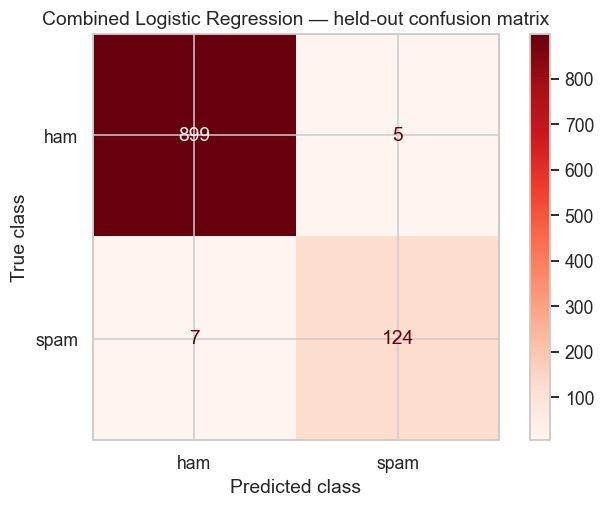

Positive spam coefficients


,coefficient
phone_present,3.251
digit_count,3.122
short_code_present,2.687
url_present,2.583
currency_present,2.518
trigger:mobile,2.352
text,2.222
num,2.222
trigger:reply,2.089
trigger:won,2.078


Negative spam coefficients


,coefficient
first_person_present,-1.289
emoticon_count,-1.259
trigger:my,-0.996
at,-0.869
that,-0.711
in,-0.694
it,-0.640
its,-0.637
t,-0.630
trigger:lol,-0.608


Compare top positive coefficient terms with distinctive log-odds:


,logistic_coefficient,log_odds_z
text,2.222,9.502
num,2.222,-0.404
for,1.924,2.509


False Positive examples (up to 10)


,label,predicted,message_raw
0,ham,spam,Glad to see your reply.
1,ham,spam,I (Career Tel) have added u as a contact on IN...
2,ham,spam,Plz note: if anyone calling from a mobile Co. ...
3,ham,spam,"""Si.como no?!listened2the plaid album-quite gd..."
4,ham,spam,Your bill at 3 is £33.65 so thats not bad!


False Negative examples (up to 10)


,label,predicted,message_raw
0,spam,ham,You will recieve your tone within the next 24h...
1,spam,ham,Burger King - Wanna play footy at a top stadiu...
2,spam,ham,Xmas & New Years Eve tickets are now on sale f...
3,spam,ham,Would you like to see my XXX pics they are so ...
4,spam,ham,Babe: U want me dont u baby! Im nasty and have...
5,spam,ham,In The Simpsons Movie released in July 2007 na...
6,spam,ham,"Latest News! Police station toilet stolen, cop..."


**Error analysis:** False positives commonly include promotional or transactional language in legitimate messages; false negatives can be short, obfuscated, or atypical spam. Inspect the displayed examples rather than assuming a fixed cause.

In [35]:

from scipy.sparse import csr_matrix, hstack
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_validate
from sklearn.preprocessing import MinMaxScaler
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (
    precision_recall_fscore_support,
    roc_auc_score,
    average_precision_score,
    ConfusionMatrixDisplay
)
from sklearn.base import clone

# Convert SMS messages into TF-IDF features
X_text_all = TfidfVectorizer(
    ngram_range=(1, 2),
    min_df=2,
    max_features=30000,
    token_pattern=r'(?u)\b\w+\b'
).fit_transform(df.normalized_text)

# Prepare engineered numerical and binary features
engineered_cols = BINARY_FEATURES + NUMERIC_FEATURES

X_eng_all = csr_matrix(
    MinMaxScaler().fit_transform(
        df[engineered_cols].astype(float)
    )
)

# Create three input datasets
X_all = {
    'TF-IDF only': X_text_all,
    'Engineered only': X_eng_all,
    'Combined': hstack([X_text_all, X_eng_all]).tocsr()
}

# Convert labels into numerical values
y = (df.label == 'spam').astype(int).to_numpy()

# Split data into training and testing sets
train_idx, test_idx = train_test_split(
    np.arange(len(df)),
    test_size=CONFIG['test_size'],
    random_state=CONFIG['seed'],
    stratify=y
)

# Define machine learning models
models = {
    'Logistic Regression': LogisticRegression(
        max_iter=1500,
        class_weight='balanced',
        random_state=CONFIG['seed']
    ),
    'Multinomial Naive Bayes': MultinomialNB()
}

# Configure five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=CONFIG['seed']
)

# Define evaluation metrics
scoring = {
    'precision': 'precision',
    'recall': 'recall',
    'f1': 'f1',
    'roc_auc': 'roc_auc',
    'pr_auc': 'average_precision'
}

model_rows = []
fitted = {}

# Train and evaluate every model with each input type
for input_name, X in X_all.items():

    for model_name, estimator in models.items():

        scores = cross_validate(
            clone(estimator),
            X[train_idx],
            y[train_idx],
            cv=cv,
            scoring=scoring,
            n_jobs=1
        )

        # Train the model on the complete training set
        fitted_model = clone(estimator).fit(
            X[train_idx],
            y[train_idx]
        )

        # Predict spam probabilities on the test set
        prob = fitted_model.predict_proba(X[test_idx])[:, 1]
        pred = (prob >= 0.5).astype(int)

        # Calculate holdout metrics
        pr, rc, f1, _ = precision_recall_fscore_support(
            y[test_idx],
            pred,
            average='binary',
            zero_division=0
        )

        model_rows.append({
            'input': input_name,
            'model': model_name,
            'holdout_precision': pr,
            'holdout_recall': rc,
            'holdout_f1': f1,
            'holdout_roc_auc': roc_auc_score(y[test_idx], prob),
            'holdout_pr_auc': average_precision_score(y[test_idx], prob),
            **{
                f'cv_{metric}': scores[f'test_{metric}'].mean()
                for metric in scoring
            }
        })

        fitted[(input_name, model_name)] = fitted_model


# Display model comparison
model_results = pd.DataFrame(model_rows)
display(model_results.round(3))


# Identify the model with the highest holdout F1-score
best_row = model_results.sort_values(
    'holdout_f1',
    ascending=False
).iloc[0]

display(Markdown(
    f"**Key takeaway — baseline:** "
    f"Best holdout F1 is {best_row.holdout_f1:.3f} "
    f"for {best_row['model']} using {best_row['input']} "
    f"(ROC-AUC {best_row.holdout_roc_auc:.3f}, "
    f"PR-AUC {best_row.holdout_pr_auc:.3f})."
))


# Evaluate the combined Logistic Regression model
chosen = fitted[('Combined', 'Logistic Regression')]

test_pred = chosen.predict(X_all['Combined'][test_idx])

ConfusionMatrixDisplay.from_predictions(
    y[test_idx],
    test_pred,
    display_labels=['ham', 'spam'],
    cmap='Reds',
    values_format='d'
)

plt.title('Combined Logistic Regression — held-out confusion matrix')
plt.xlabel('Predicted class')
plt.ylabel('True class')
plt.tight_layout()
plt.show()


# Extract Logistic Regression coefficients
combined_feature_names = list(
    TfidfVectorizer(
        ngram_range=(1, 2),
        min_df=2,
        max_features=30000,
        token_pattern=r'(?u)\b\w+\b'
    ).fit(df.normalized_text).get_feature_names_out()
) + engineered_cols

coef = pd.Series(
    chosen.coef_[0],
    index=combined_feature_names
)

print('Positive spam coefficients')
display(
    coef.nlargest(20)
        .rename('coefficient')
        .to_frame()
        .round(3)
)

print('Negative spam coefficients')
display(
    coef.nsmallest(20)
        .rename('coefficient')
        .to_frame()
        .round(3)
)


# Compare model coefficients with distinctive vocabulary
print('Compare top positive coefficient terms with distinctive log-odds:')

display(
    pd.concat([
        coef.nlargest(15).rename('logistic_coefficient'),
        distinctive.set_index('term').z_score.rename('log_odds_z')
    ], axis=1)
    .dropna()
    .head(15)
    .round(3)
)


# Examine false positive and false negative predictions
error_df = df.iloc[test_idx][
    ['label', 'message_raw']
].copy()

error_df['predicted'] = np.where(
    test_pred == 1,
    'spam',
    'ham'
)

error_df['error_type'] = np.select(
    [
        (y[test_idx] == 0) & (test_pred == 1),
        (y[test_idx] == 1) & (test_pred == 0)
    ],
    [
        'false positive',
        'false negative'
    ],
    default='correct'
)

for error_type in ['false positive', 'false negative']:

    print(f'{error_type.title()} examples (up to 10)')

    display(
        error_df[error_df.error_type == error_type][
            ['label', 'predicted', 'message_raw']
        ]
        .head(10)
        .reset_index(drop=True)
    )


# Display error analysis takeaway
display(Markdown(
    '**Error analysis:** False positives commonly include promotional '
    'or transactional language in legitimate messages; false negatives '
    'can be short, obfuscated, or atypical spam. Inspect the displayed '
    'examples rather than assuming a fixed cause.'
))


## 14. Conclusion and limitations

The executed tables, figures, and examples show how this corpus expresses spam through message length, promotional vocabulary, numeric and monetary cues, and grouped lexical families. No single feature is a reliable policy by itself.

**Limitations:** the corpus is old and small; spam is heavily templated; phone and currency regexes are heuristic; multiple comparisons can still yield unstable rare associations; and language and number formats are UK-centric. Random splits can leak near-duplicate templates across train and test.

**Future work:** validate on a current, source-disjoint corpus; quantify uncertainty with bootstrap intervals; audit language and demographic bias; inspect cluster labels with domain experts; and evaluate temporal drift before using any classifier operationally.